# Projeto de IA — Modelagem de Ciclos de Atividade Solar
## Notebook 05 — Comparação entre ARIMA e Random Forest

**Objetivo:** reunir as previsões produzidas nos Notebooks 03 e 04, comparar ARIMA e Random Forest no mesmo período de teste e examinar o comportamento dos erros ao longo do ciclo solar.

Este notebook não treina novamente os modelos. Ele analisa os arquivos CSV exportados pelas etapas anteriores. Por isso, execute primeiro os Notebooks 03 e 04 e mantenha os CSVs na mesma pasta deste arquivo (ou ajuste `PASTA_RESULTADOS` na próxima célula).

**Desenho da avaliação:** 40 previsões anuais de um passo à frente, entre 1969 e 2008. Em cada ano de teste, cada modelo prevê antes de receber o valor observado daquele ano; depois, esse valor pode ser incorporado ao histórico para a previsão seguinte.

## 1. Preparação do ambiente e leitura dos resultados

Os arquivos esperados são `sunspots_previsoes_arima.csv` e `sunspots_previsoes_random_forest.csv`. Os dados reais, os anos e as previsões são verificados antes da comparação.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import wilcoxon
from statsmodels.datasets import sunspots
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (13, 5)
plt.rcParams["axes.grid"] = True

# Se os CSVs estiverem em outra pasta, altere esta variável.
PASTA_RESULTADOS = Path(".")
ARQUIVO_ARIMA = PASTA_RESULTADOS / "sunspots_previsoes_arima.csv"
ARQUIVO_RF = PASTA_RESULTADOS / "sunspots_previsoes_random_forest.csv"

for caminho in [ARQUIVO_ARIMA, ARQUIVO_RF]:
    if not caminho.exists():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {caminho.resolve()}\n"
            "Execute os Notebooks 03 e 04 e coloque os CSVs na mesma pasta deste notebook."
        )

arima = pd.read_csv(ARQUIVO_ARIMA).set_index("ano").sort_index()
rf = pd.read_csv(ARQUIVO_RF).set_index("ano").sort_index()

print("Arquivos carregados.")
print(f"ARIMA: {len(arima)} previsões | RF: {len(rf)} previsões")
display(arima.head())
display(rf.head())

Arquivos carregados.
ARIMA: 40 previsões | RF: 40 previsões


,real,previsao_arima,limite_inferior_95,limite_superior_95,erro,erro_absoluto
ano,,,,,,
1969,105.500,114.875,85.648,144.101,-9.375,9.375
1970,104.500,98.095,68.909,127.281,6.405,6.405
1971,66.600,92.650,63.512,121.787,-26.050,26.050
1972,68.900,31.872,2.624,61.120,37.028,37.028
1973,38.000,55.450,25.872,85.028,-17.450,17.450


,real,previsao_rf,erro,erro_absoluto
ano,,,,
1969,105.500,115.134,-9.634,9.634
1970,104.500,92.838,11.662,11.662
1971,66.600,74.292,-7.692,7.692
1972,68.900,51.211,17.689,17.689
1973,38.000,50.620,-12.620,12.620


## 2. Verificação de comparabilidade

Uma comparação só é válida se os dois modelos tiverem sido avaliados nos mesmos anos e contra os mesmos valores reais. A célula abaixo interrompe a execução caso encontre diferenças.

In [2]:
if not arima.index.equals(rf.index):
    raise ValueError("ARIMA e Random Forest não têm exatamente os mesmos anos de teste.")

if not np.allclose(arima["real"].to_numpy(), rf["real"].to_numpy(), rtol=0, atol=1e-9):
    raise ValueError("Os valores reais associados às previsões não coincidem.")

comparacao = pd.DataFrame(index=arima.index)
comparacao.index.name = "ano"
comparacao["real"] = arima["real"].astype(float)
comparacao["ARIMA"] = arima["previsao_arima"].astype(float)
comparacao["Random Forest"] = rf["previsao_rf"].astype(float)

if len(comparacao) != 40:
    warnings.warn(f"O período contém {len(comparacao)} anos, e não os 40 planejados.")

print(f"Período comum: {comparacao.index.min()}–{comparacao.index.max()}")
print(f"Número de anos comparados: {len(comparacao)}")
print("Valores reais coincidentes: sim")
display(comparacao.head(10).round(2))

Período comum: 1969–2008
Número de anos comparados: 40
Valores reais coincidentes: sim


,real,ARIMA,Random Forest
ano,,,
1969,105.500,114.870,115.130
1970,104.500,98.090,92.840
1971,66.600,92.650,74.290
1972,68.900,31.870,51.210
1973,38.000,55.450,50.620
1974,34.500,23.470,23.010
1975,15.500,30.560,27.730
1976,12.600,28.200,17.630
1977,27.500,26.160,24.310


## 3. Métricas calculadas com uma função única

Usaremos as quatro métricas pedidas no projeto:

- **MAE:** erro absoluto médio, na escala do número de manchas solares.
- **RMSE:** penaliza mais os erros grandes.
- **MAPE:** erro percentual absoluto médio. É instável quando o valor real se aproxima de zero; o código informa quantas observações entram no cálculo.
- **R²:** compara o erro do modelo com a variabilidade dos valores reais no teste. Não mede explicação causal ou física.

Como complemento, calcularemos **sMAPE**, **WAPE** e viés médio. Esses indicadores ajudam a interpretar o MAPE e a direção dos erros, mas não substituem as métricas exigidas.

In [3]:
def calcular_metricas(y_real, y_previsto):
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.asarray(y_previsto, dtype=float)
    mascara_mape = np.abs(y_real) > 1e-8

    mape = (
        mean_absolute_percentage_error(y_real[mascara_mape], y_previsto[mascara_mape]) * 100
        if mascara_mape.any() else np.nan
    )
    denominador_smape = np.abs(y_real) + np.abs(y_previsto)
    mascara_smape = denominador_smape > 1e-8
    smape = (
        np.mean(2 * np.abs(y_real[mascara_smape] - y_previsto[mascara_smape])
                / denominador_smape[mascara_smape]) * 100
        if mascara_smape.any() else np.nan
    )
    wape = (
        np.sum(np.abs(y_real - y_previsto)) / np.sum(np.abs(y_real)) * 100
        if np.sum(np.abs(y_real)) > 1e-8 else np.nan
    )

    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "MAPE (%)": mape,
        "Pontos no MAPE": int(mascara_mape.sum()),
        "R²": r2_score(y_real, y_previsto),
        "sMAPE (%)": smape,
        "WAPE (%)": wape,
        # Viés = real - previsto; positivo indica subestimação média.
        "Viés (real - previsto)": np.mean(y_real - y_previsto),
    }

y_real = comparacao["real"].to_numpy()
metricas_modelos = pd.DataFrame({
    nome: calcular_metricas(y_real, comparacao[nome].to_numpy())
    for nome in ["ARIMA", "Random Forest"]
}).T

print("Métricas no mesmo período de teste:")
display(metricas_modelos.round(3))

Métricas no mesmo período de teste:


,MAE,RMSE,MAPE (%),Pontos no MAPE,R²,sMAPE (%),WAPE (%),Viés (real - previsto)
ARIMA,14.972,18.257,58.060,40.000,0.858,34.204,21.939,-1.204
Random Forest,12.726,16.795,45.760,40.000,0.879,26.577,18.648,2.278


## 4. Inclusão de referências simples

Para saber se os modelos complexos agregam valor, vamos reconstruir duas referências usando somente informações disponíveis em cada ano:

- **Persistência:** prevê que o próximo ano terá o mesmo valor do último ano observado.
- **Sazonal ingênuo de 11 anos:** prevê o valor observado 11 anos antes.

Essas referências não são concorrentes sofisticadas; funcionam como pontos de comparação. O valor real de cada ano só entra no histórico depois de a previsão daquele ano ser registrada.

In [4]:
base = sunspots.load_pandas().data.copy()
base["YEAR"] = base["YEAR"].astype(int)
serie_completa = base.set_index("YEAR")["SUNACTIVITY"].astype(float).sort_index()

anos_teste = comparacao.index.to_numpy(dtype=int)
if not np.all(np.isin(anos_teste, serie_completa.index)):
    raise ValueError("Há anos do teste que não estão na série oficial carregada pelo Statsmodels.")

valores_referencia = serie_completa.loc[anos_teste].to_numpy(dtype=float)
if not np.allclose(comparacao["real"].to_numpy(dtype=float), valores_referencia, rtol=0, atol=1e-8):
    raise ValueError("Os valores reais dos CSVs não coincidem com a série de referência do Statsmodels.")

# O treino termina imediatamente antes do primeiro ano avaliado.
historico = serie_completa.loc[serie_completa.index < anos_teste[0]].to_numpy(dtype=float)
previsao_persistencia = []
previsao_sazonal_11 = []

for ano in anos_teste:
    if len(historico) < 11:
        raise ValueError("Histórico insuficiente para a referência sazonal de 11 anos.")
    previsao_persistencia.append(float(historico[-1]))
    previsao_sazonal_11.append(float(historico[-11]))
    valor_real_ano = float(serie_completa.loc[ano])
    historico = np.append(historico, valor_real_ano)

comparacao["Persistência"] = previsao_persistencia
comparacao["Sazonal ingênuo (11 anos)"] = previsao_sazonal_11

metricas_completas = pd.DataFrame({
    nome: calcular_metricas(y_real, comparacao[nome].to_numpy())
    for nome in ["ARIMA", "Random Forest", "Persistência", "Sazonal ingênuo (11 anos)"]
}).T

print("Comparação ampliada com referências simples:")
display(metricas_completas.round(3))

Comparação ampliada com referências simples:


,MAE,RMSE,MAPE (%),Pontos no MAPE,R²,sMAPE (%),WAPE (%),Viés (real - previsto)
ARIMA,14.972,18.257,58.060,40.000,0.858,34.204,21.939,-1.204
Random Forest,12.726,16.795,45.760,40.000,0.879,26.577,18.648,2.278
Persistência,22.745,29.889,51.769,40.000,0.618,45.104,33.328,-2.575
Sazonal ingênuo (11 anos),25.725,33.961,57.996,40.000,0.507,40.907,37.695,-4.895


## 5. Gráfico principal: valores reais e previsões

Observe se cada modelo acompanha a subida e a descida dos ciclos. Um modelo pode acertar a tendência geral e, ainda assim, suavizar ou atrasar os máximos e mínimos.

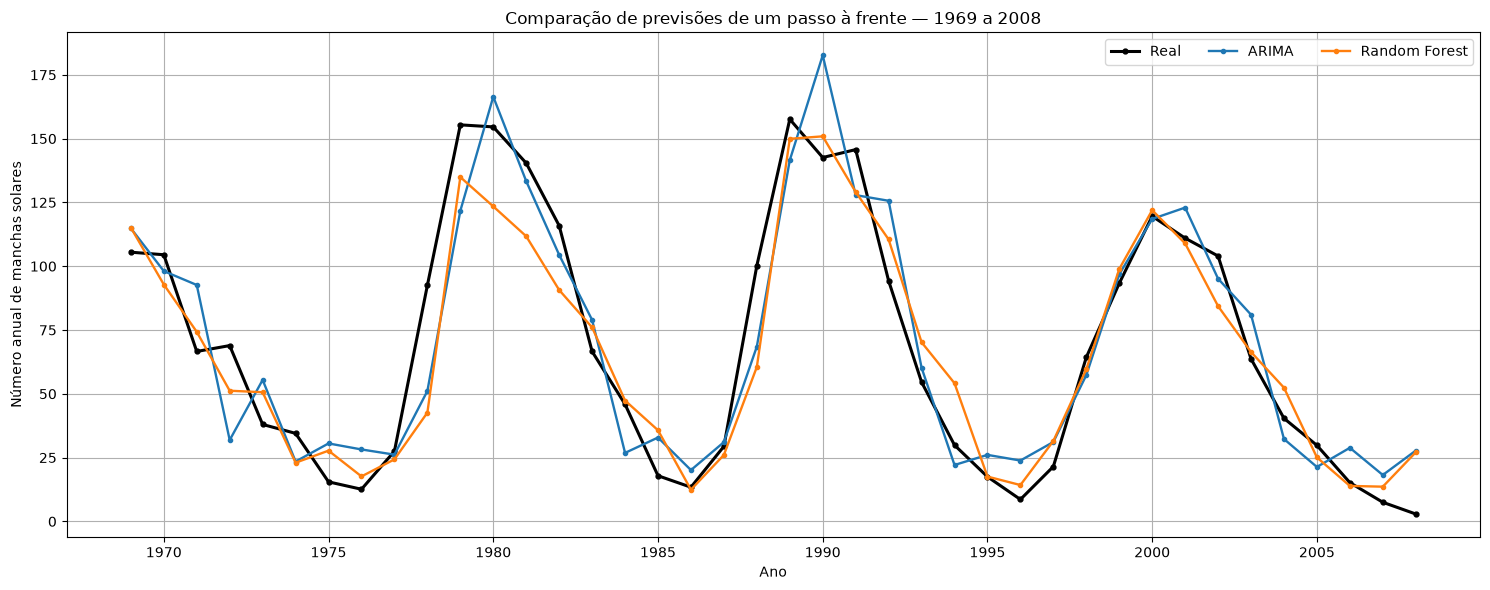

In [5]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(comparacao.index, comparacao["real"], color="black", linewidth=2.2,
        marker="o", markersize=3.5, label="Real")
ax.plot(comparacao.index, comparacao["ARIMA"], linewidth=1.7,
        marker=".", label="ARIMA")
ax.plot(comparacao.index, comparacao["Random Forest"], linewidth=1.7,
        marker=".", label="Random Forest")
ax.set(title="Comparação de previsões de um passo à frente — 1969 a 2008",
       xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

## 6. Comparação dos erros ao longo do tempo

Erro assinado é definido como `real − previsto`. Valor positivo significa que o modelo subestimou a atividade observada; valor negativo significa superestimação. O erro absoluto ignora essa direção e mede o tamanho do desvio.

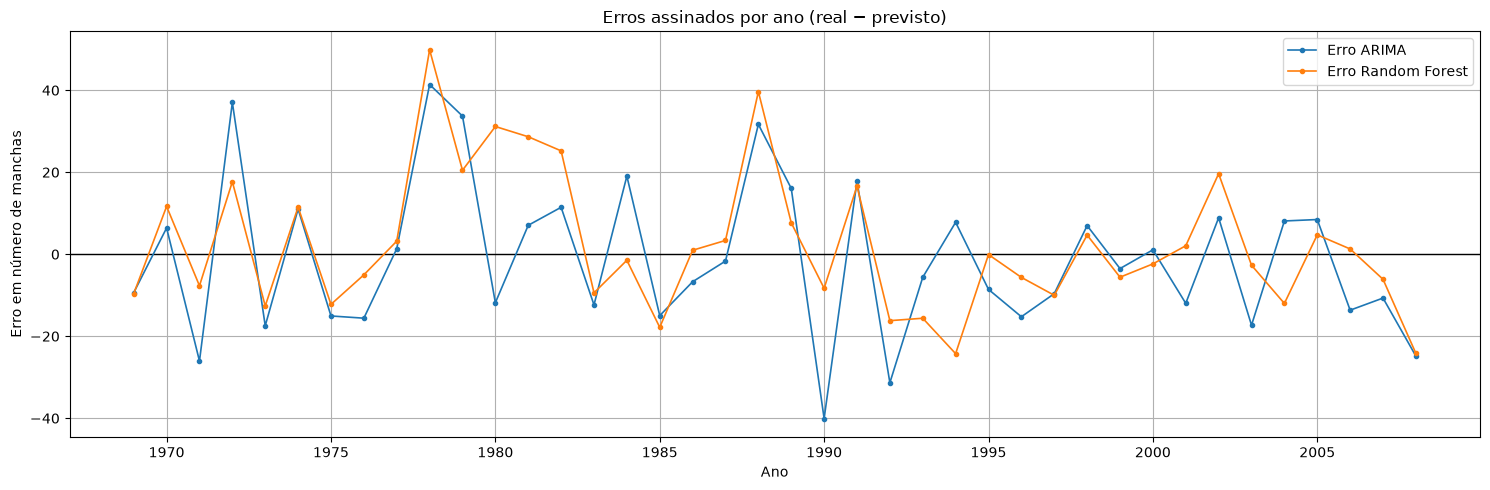

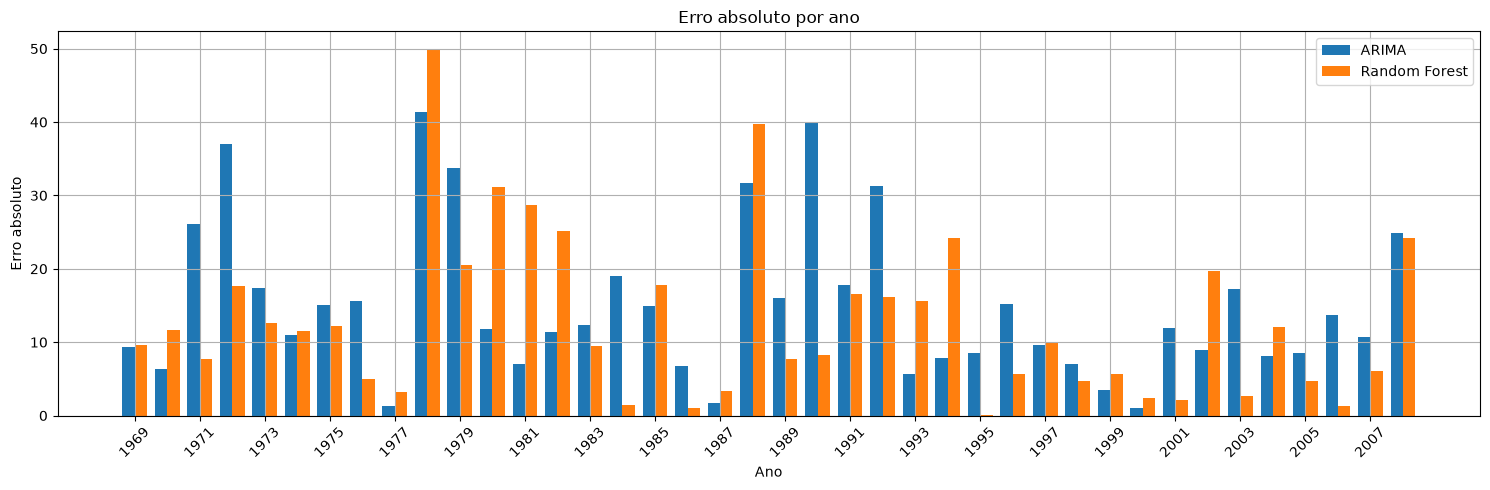

In [6]:
for nome in ["ARIMA", "Random Forest"]:
    comparacao[f"erro_{nome}"] = comparacao["real"] - comparacao[nome]
    comparacao[f"erro_abs_{nome}"] = comparacao[f"erro_{nome}"].abs()

fig, ax = plt.subplots(figsize=(15, 5))
ax.axhline(0, color="black", linewidth=1)
ax.plot(comparacao.index, comparacao["erro_ARIMA"], marker="o", markersize=3,
        linewidth=1.2, label="Erro ARIMA")
ax.plot(comparacao.index, comparacao["erro_Random Forest"], marker="o", markersize=3,
        linewidth=1.2, label="Erro Random Forest")
ax.set(title="Erros assinados por ano (real − previsto)",
       xlabel="Ano", ylabel="Erro em número de manchas")
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(15, 5))
largura = 0.38
x = np.arange(len(comparacao))
ax.bar(x - largura/2, comparacao["erro_abs_ARIMA"], width=largura, label="ARIMA")
ax.bar(x + largura/2, comparacao["erro_abs_Random Forest"], width=largura, label="Random Forest")
ax.set_xticks(x[::2], comparacao.index.to_numpy()[::2], rotation=45)
ax.set(title="Erro absoluto por ano", xlabel="Ano", ylabel="Erro absoluto")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Em quais anos os modelos mais erraram?

A tabela ordena os anos pelo erro absoluto de cada modelo. Use-a para investigar se os erros maiores ocorrem em transições rápidas, picos ou vales.

In [7]:
colunas_tabela = ["real", "ARIMA", "Random Forest",
                  "erro_ARIMA", "erro_Random Forest",
                  "erro_abs_ARIMA", "erro_abs_Random Forest"]
print("Dez maiores erros absolutos do ARIMA:")
display(comparacao[colunas_tabela].sort_values("erro_abs_ARIMA", ascending=False).head(10).round(2))

print("Dez maiores erros absolutos do Random Forest:")
display(comparacao[colunas_tabela].sort_values("erro_abs_Random Forest", ascending=False).head(10).round(2))

Dez maiores erros absolutos do ARIMA:


,real,ARIMA,Random Forest,erro_ARIMA,erro_Random Forest,erro_abs_ARIMA,erro_abs_Random Forest
ano,,,,,,,
1978,92.500,51.110,42.630,41.390,49.870,41.390,49.870
1990,142.600,182.670,150.900,-40.070,-8.300,40.070,8.300
1972,68.900,31.870,51.210,37.030,17.690,37.030,17.690
1979,155.400,121.700,134.920,33.700,20.480,33.700,20.480
1988,100.200,68.520,60.530,31.680,39.670,31.680,39.670
1992,94.300,125.650,110.500,-31.350,-16.200,31.350,16.200
1971,66.600,92.650,74.290,-26.050,-7.690,26.050,7.690
2008,2.900,27.750,27.090,-24.850,-24.190,24.850,24.190
1984,45.900,26.850,47.370,19.050,-1.470,19.050,1.470


Dez maiores erros absolutos do Random Forest:


,real,ARIMA,Random Forest,erro_ARIMA,erro_Random Forest,erro_abs_ARIMA,erro_abs_Random Forest
ano,,,,,,,
1978,92.500,51.110,42.630,41.390,49.870,41.390,49.870
1988,100.200,68.520,60.530,31.680,39.670,31.680,39.670
1980,154.600,166.430,123.440,-11.830,31.160,11.830,31.160
1981,140.400,133.340,111.740,7.060,28.660,7.060,28.660
1982,115.900,104.450,90.680,11.450,25.220,11.450,25.220
1994,29.900,22.110,54.150,7.790,-24.250,7.790,24.250
2008,2.900,27.750,27.090,-24.850,-24.190,24.850,24.190
1979,155.400,121.700,134.920,33.700,20.480,33.700,20.480
2002,104.000,95.110,84.360,8.890,19.640,8.890,19.640


## 8. Desempenho perto dos máximos e mínimos observados

Para uma leitura exploratória, detectaremos máximos e mínimos locais dentro do intervalo de teste com `find_peaks`, usando distância mínima de 7 anos e proeminência mínima de 10 unidades. Em seguida, compararemos o erro absoluto no ano extremo e na janela de um ano antes até um ano depois.

**Limitação importante:** essa detecção é feita sobre os valores reais do teste, portanto serve para análise retrospectiva dos erros, não para selecionar ou treinar modelos. Extremos nas bordas do intervalo podem não ser detectados porque o algoritmo precisa de vizinhos em ambos os lados.

Extremos locais detectados no período de teste:


,tipo,ano,valor_real,erro_abs_ARIMA_no_extremo,erro_abs_RF_no_extremo
0,Pico,1979,155.400,33.700,20.480
1,Pico,1989,157.600,16.060,7.670
2,Pico,2000,119.600,1.070,2.360
3,Vale,1976,12.600,15.600,5.030
4,Vale,1986,13.400,6.710,0.970
5,Vale,1996,8.600,15.250,5.650


Erro médio nas janelas de ±1 ano ao redor dos extremos detectados:


,Região,Anos incluídos,N observações,MAE local ARIMA,MAE local Random Forest
0,Picos,"1978, 1979, 1980, 1988, 1989, 1990, 1999, 2000...",9,21.254,18.575
1,Vales,"1975, 1976, 1977, 1985, 1986, 1987, 1995, 1996...",9,9.865,6.482


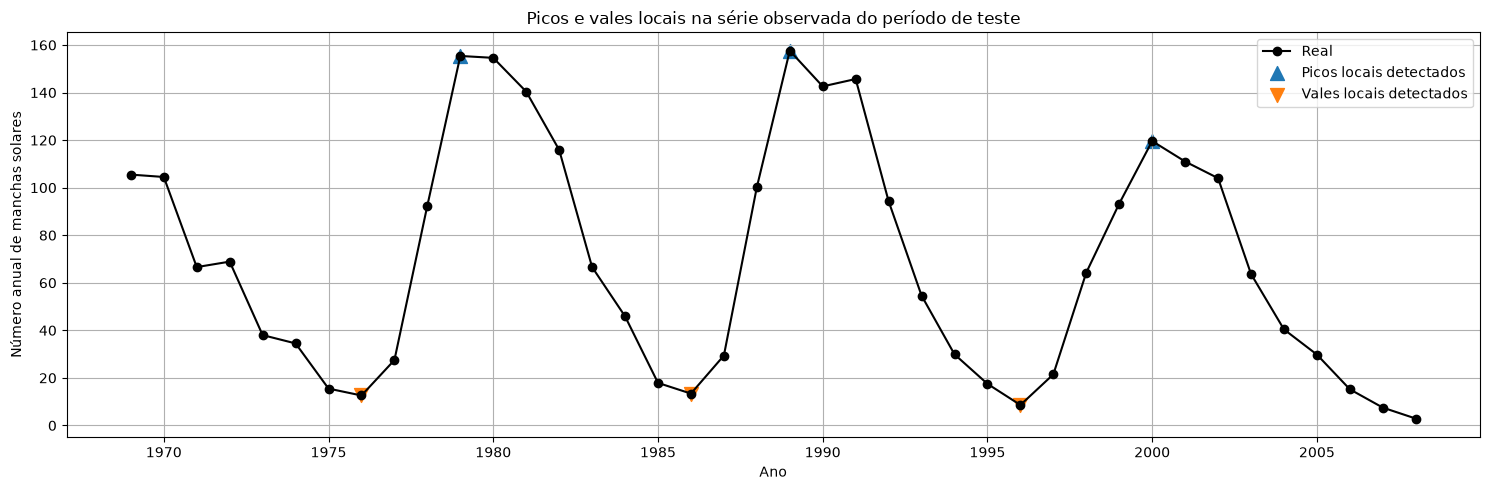

In [8]:
valores = comparacao["real"].to_numpy(dtype=float)
anos = comparacao.index.to_numpy(dtype=int)

indices_picos, _ = find_peaks(valores, distance=7, prominence=10)
indices_vales, _ = find_peaks(-valores, distance=7, prominence=10)

extremos = []
for tipo, indices in [("Pico", indices_picos), ("Vale", indices_vales)]:
    for i in indices:
        extremos.append({
            "tipo": tipo,
            "ano": int(anos[i]),
            "valor_real": float(valores[i]),
            "erro_abs_ARIMA_no_extremo": float(comparacao.iloc[i]["erro_abs_ARIMA"]),
            "erro_abs_RF_no_extremo": float(comparacao.iloc[i]["erro_abs_Random Forest"]),
        })

tabela_extremos = pd.DataFrame(extremos)
print("Extremos locais detectados no período de teste:")
display(tabela_extremos.round(2))

resumo_janelas = []
for tipo, indices in [("Picos", indices_picos), ("Vales", indices_vales)]:
    indices_janela = sorted({j for i in indices for j in range(max(0, i-1), min(len(comparacao), i+2))})
    if indices_janela:
        bloco = comparacao.iloc[indices_janela]
        resumo_janelas.append({
            "Região": tipo,
            "Anos incluídos": ", ".join(map(str, bloco.index.to_list())),
            "N observações": len(bloco),
            "MAE local ARIMA": bloco["erro_abs_ARIMA"].mean(),
            "MAE local Random Forest": bloco["erro_abs_Random Forest"].mean(),
        })

resumo_extremos = pd.DataFrame(resumo_janelas)
print("Erro médio nas janelas de ±1 ano ao redor dos extremos detectados:")
display(resumo_extremos.round(3))

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(comparacao.index, comparacao["real"], color="black", marker="o", label="Real")
ax.scatter(anos[indices_picos], valores[indices_picos], marker="^", s=100,
           label="Picos locais detectados")
ax.scatter(anos[indices_vales], valores[indices_vales], marker="v", s=100,
           label="Vales locais detectados")
ax.set(title="Picos e vales locais na série observada do período de teste",
       xlabel="Ano", ylabel="Número anual de manchas solares")
ax.legend()
plt.tight_layout()
plt.show()

## 9. Comparação pareada dos erros absolutos

Cada ano produz um par de erros absolutos: um do ARIMA e outro do Random Forest. O teste de postos sinalizados de Wilcoxon examina se há evidência de uma diferença sistemática entre esses erros pareados.

O teste é complementar, não obrigatório para o projeto. Com apenas 40 anos e uma série temporal, o resultado deve ser interpretado com prudência. O teste de Wilcoxon usual pressupõe independência entre as diferenças pareadas; como erros de anos consecutivos podem apresentar dependência temporal, o p-valor é apenas exploratório. Ele não transforma a avaliação em uma prova universal de superioridade.

In [9]:
erro_a = comparacao["erro_abs_ARIMA"].to_numpy(dtype=float)
erro_rf = comparacao["erro_abs_Random Forest"].to_numpy(dtype=float)
diferenca = erro_a - erro_rf  # positivo: erro do RF foi menor naquele ano

print(f"Anos em que RF teve erro absoluto menor: {(diferenca > 0).sum()} de {len(diferenca)}")
print(f"Anos em que ARIMA teve erro absoluto menor: {(diferenca < 0).sum()} de {len(diferenca)}")
print(f"Diferença média MAE (ARIMA − RF): {diferenca.mean():.3f}")

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    teste_wilcoxon = wilcoxon(erro_a, erro_rf, alternative="two-sided", zero_method="wilcox")

print(f"Wilcoxon: estatística = {teste_wilcoxon.statistic:.3f}; p-valor = {teste_wilcoxon.pvalue:.4f}")
if teste_wilcoxon.pvalue < 0.05:
    print("Neste teste, há evidência de diferença entre os erros absolutos pareados ao nível de 5%.")
else:
    print("Neste teste, não há evidência suficiente de diferença entre os erros absolutos pareados ao nível de 5%.")
print("A ausência de significância não prova que os modelos sejam equivalentes.")

Anos em que RF teve erro absoluto menor: 22 de 40
Anos em que ARIMA teve erro absoluto menor: 18 de 40
Diferença média MAE (ARIMA − RF): 2.246
Wilcoxon: estatística = 318.000; p-valor = 0.2214
Neste teste, não há evidência suficiente de diferença entre os erros absolutos pareados ao nível de 5%.
A ausência de significância não prova que os modelos sejam equivalentes.


## 10. Interpretação dos resultados e limites

Use os resultados exibidos acima para construir a conclusão. Alguns cuidados são essenciais:

1. **Mesmo período:** ambos os modelos foram avaliados nos mesmos 40 anos e contra os mesmos valores reais. Isso torna a comparação mais justa.
2. **Previsão de um passo à frente:** o experimento permite incorporar o valor real de um ano depois de prever esse ano. Não representa uma previsão de 40 anos feita de uma só vez em 1968.
3. **MAPE:** valores reais pequenos podem produzir percentuais muito altos. Por isso, não interprete o MAPE isoladamente; observe também MAE, RMSE, sMAPE e WAPE.
4. **Picos e vales:** modelos podem suavizar amplitudes ou atrasar pontos de virada. A análise de extremos é retrospectiva e descritiva.
5. **Importância dos lags:** a importância do Random Forest é uma medida interna do modelo, não causalidade física.
6. **Generalização:** os resultados descrevem uma única série histórica e uma janela de teste. Não provam que o mesmo modelo será melhor em outros períodos, séries ou horizontes.
7. **Incerteza:** o ARIMA disponibiliza intervalos preditivos, enquanto o Random Forest usado nesta etapa fornece previsões pontuais. A comparação de incerteza exigiria métodos adicionais para o RF.
8. **Seleção de modelo:** as ordens ARIMA e hiperparâmetros do RF foram selecionados antes da avaliação final, usando dados anteriores ao período de teste. Se a equipe mudar modelos após observar o desempenho no teste, esse período deixa de ser uma avaliação final independente.

## 11. Conclusão orientada pelos dados

A célula seguinte produz um resumo quantitativo automático. Ele ajuda a redigir o relatório, mas deve ser acompanhado de interpretação humana dos gráficos, dos erros nas transições de ciclo e dos diagnósticos feitos nos Notebooks 03 e 04.

In [10]:
mae_a = metricas_completas.loc["ARIMA", "MAE"]
mae_rf = metricas_completas.loc["Random Forest", "MAE"]
rmse_a = metricas_completas.loc["ARIMA", "RMSE"]
rmse_rf = metricas_completas.loc["Random Forest", "RMSE"]
r2_a = metricas_completas.loc["ARIMA", "R²"]
r2_rf = metricas_completas.loc["Random Forest", "R²"]

melhor_mae = "Random Forest" if mae_rf < mae_a else "ARIMA"
melhor_rmse = "Random Forest" if rmse_rf < rmse_a else "ARIMA"
melhor_r2 = "Random Forest" if r2_rf > r2_a else "ARIMA"
reducao_mae = (mae_a - mae_rf) / mae_a * 100

print(f"Período: {comparacao.index.min()}–{comparacao.index.max()} ({len(comparacao)} anos).")
print(f"Menor MAE: {melhor_mae}.")
print(f"Menor RMSE: {melhor_rmse}.")
print(f"Maior R²: {melhor_r2}.")
print(f"Diferença relativa de MAE (ARIMA para RF): {reducao_mae:.1f}%.")
print(f"Teste pareado de Wilcoxon: p = {teste_wilcoxon.pvalue:.4f}.")
print("Consulte também o MAPE e as regiões de picos/vales antes de formular uma conclusão final.")

Período: 1969–2008 (40 anos).
Menor MAE: Random Forest.
Menor RMSE: Random Forest.
Maior R²: Random Forest.
Diferença relativa de MAE (ARIMA para RF): 15.0%.
Teste pareado de Wilcoxon: p = 0.2214.
Consulte também o MAPE e as regiões de picos/vales antes de formular uma conclusão final.


## 12. Exportação das tabelas finais

Os arquivos abaixo podem ser usados no relatório e na apresentação. Eles serão salvos na pasta `resultados_comparacao`, criada ao lado deste notebook.

In [11]:
PASTA_EXPORTACAO = Path("resultados_comparacao")
PASTA_EXPORTACAO.mkdir(exist_ok=True)

metricas_completas.to_csv(PASTA_EXPORTACAO / "sunspots_comparacao_metricas.csv", index_label="modelo")
comparacao.to_csv(PASTA_EXPORTACAO / "sunspots_erros_comparados.csv", index_label="ano")
tabela_extremos.to_csv(PASTA_EXPORTACAO / "sunspots_extremos_detectados.csv", index=False)
resumo_extremos.to_csv(PASTA_EXPORTACAO / "sunspots_erros_picos_vales.csv", index=False)

print("Arquivos exportados para:", PASTA_EXPORTACAO.resolve())
for arquivo in sorted(PASTA_EXPORTACAO.glob("*.csv")):
    print("-", arquivo.name)

Arquivos exportados para: /Users/ronnyrufino/Documents/SISTEMAS-DE-INFORMACAO/Inteligência-Artificial/Projeto/resultados_comparacao
- sunspots_comparacao_metricas.csv
- sunspots_erros_comparados.csv
- sunspots_erros_picos_vales.csv
- sunspots_extremos_detectados.csv


## 13. Perguntas para a equipe

1. Os modelos foram comparados nos mesmos anos e com os mesmos valores reais? Como o código confirma isso?
2. Qual modelo teve menor MAE e RMSE? Qual teve maior R²?
3. O resultado de MAPE conta a mesma história? Como os anos de baixa atividade afetam essa métrica?
4. Quantos anos cada modelo venceu em erro absoluto? O teste de Wilcoxon encontrou evidência suficiente de diferença?
5. Nos picos e vales detectados, qual modelo apresentou menor erro médio nas janelas de ±1 ano?
6. Os gráficos sugerem que algum modelo suaviza os máximos ou demora para acompanhar mudanças?
7. O que muda ao comparar a previsão de um passo à frente com uma previsão de vários anos sem atualização do histórico?
8. Quais limitações impedem afirmar que um modelo é universalmente superior?

### Modelo de estrutura para a conclusão do relatório

> Os modelos ARIMA e Random Forest foram avaliados em um procedimento cronológico de previsões de um passo à frente para o período de 1969 a 2008. A comparação foi realizada sobre os mesmos anos e valores observados, utilizando MAE, RMSE, MAPE e R². Os resultados indicaram que [descrever as métricas efetivamente observadas]. A análise dos erros por ano e nas proximidades de máximos e mínimos mostrou que [descrever os padrões observados]. Apesar do desempenho obtido, a interpretação deve considerar [mencionar MAPE em valores baixos, autocorrelação residual do ARIMA, possível sobreajuste do RF e limite do horizonte de um passo]. Assim, os experimentos permitem concluir que [conclusão delimitada à série e ao desenho avaliados], mas não demonstram superioridade universal de um dos métodos.

## 14. Encerramento do projeto experimental

Com este notebook, a equipe possui um fluxo completo de exploração, análise estatística, modelagem ARIMA, modelagem Random Forest e comparação. Antes de entregar:

- execute todos os notebooks em sequência, do 01 ao 05;
- confira se os CSVs e os gráficos foram gerados;
- registre versões das bibliotecas e decisões metodológicas;
- escreva a conclusão com os resultados realmente obtidos;
- inclua as limitações e não apresente correlação ou importância de atributos como causalidade física.